In [1]:
# ============================================================
# Notebook setup
# ============================================================

%load_ext autoreload
%autoreload 2

# Control figure size
figsize=(15, 4)

from util import util
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import warnings
warnings.simplefilter("ignore")
from matplotlib import pyplot as plt

# Specify datafile
data_file = os.path.join('..', 'data', 'vegashrinker.csv')
# Read data
data = pd.read_csv(data_file)
# Define the input feature
feat_in_r = data.columns[[0, 6, 7, 9, 11, 12, 13]]
# Apply binning
aggmap = {a: ['mean', 'std', 'skew'] for a in feat_in_r}
aggmap['mode'] = 'first'
aggmap['pSpintor::VAX_speed'] = 'first'
binsize = 512 # 2 seconds of measurements
bins = []
for sname, sdata in data.groupby('segment'):
    sdata['bin'] = sdata.index // binsize # Build the bin numbers
    tmp = sdata.groupby('bin').agg(aggmap) # Apply the aggregation functions
    bins.append(tmp)
data_b = pd.concat(bins)

# Baseline Approach

## Train/Test Split

**We'll try to detect the component state by learning an autoencoder**

* We'll train a model on the earlier data
* ...And then use the reconstruction error as a proxy for component wear

**We start as usual by splitting the training and test set**

In [2]:
tr_sep = int(0.5 * len(data_b))
data_b_tr = data_b.iloc[:tr_sep]
data_b_ts = data_b.iloc[tr_sep:]

...And then by standardizing our data

In [3]:
scaler = StandardScaler()
data_b_s_tr = scaler.fit_transform(data_b_tr)
data_b_s_ts = scaler.transform(data_b_ts)
data_b_s = pd.DataFrame(columns=data_b.columns, data=np.vstack([data_b_s_tr, data_b_s_ts]))

## Training and Autoencoder

**Now we can build and train the autoencoder**

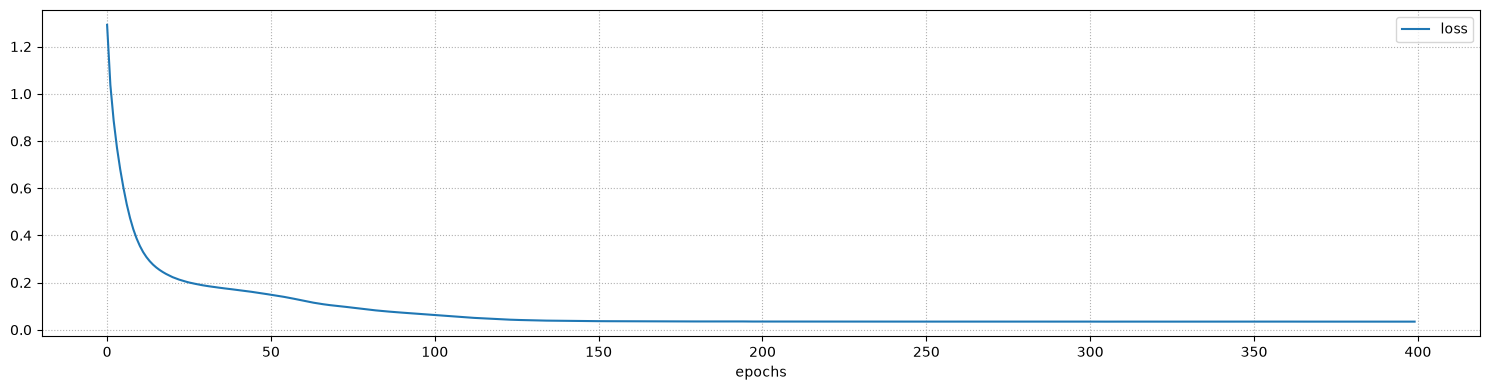

Final loss: 0.0345 (training)


In [4]:
nn = util.build_nn_model(input_shape=(len(data_b.columns),), output_shape=len(data_b.columns),
                         hidden=[len(data_b.columns)//2])
history = util.train_nn_model(nn, data_b_s_tr, data_b_s_tr, loss='mse', validation_split=0.0,
                              batch_size=32, epochs=400)
util.plot_training_history(history, figsize=figsize)

* We need many epochs to compensate for the small number of samples

## Evaluation

**Let's check the reconstruction error**

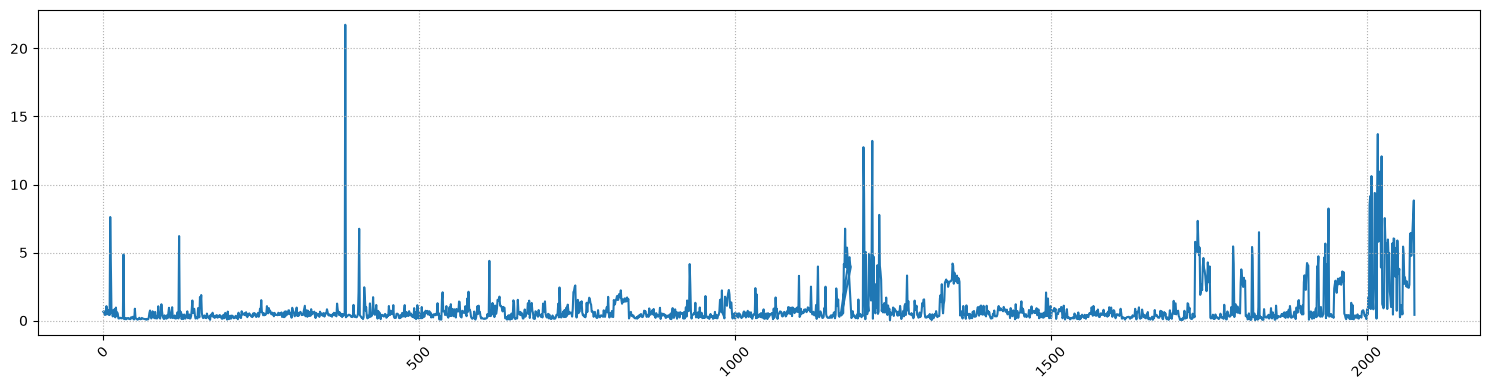

In [5]:
pred = nn.predict(data_b_s, verbose=0)
se = (data_b_s - pred)**2
sse = pd.Series(index=data_b.index, data=np.sum(se, axis=1))
util.plot_series(sse, figsize=figsize)

* Since we have a single run, we will limit ourselves to a visual inspection
* ...And the signal does not look very clear

## Evaluation

**We can gain more information by checking the individual errors**

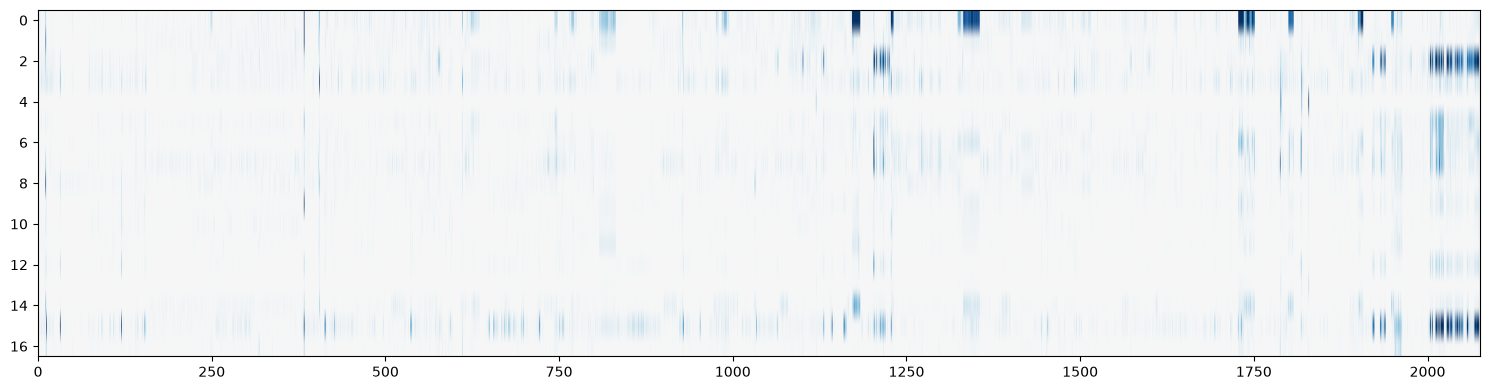

In [6]:
util.plot_dataframe(se, figsize=figsize)

* Reconstruction errors are large for different features over time

<div class=big>Do you think we can improve these results? How?</div>

# Altering the Training Distribution

## Distribution Discrepancy

**A major problem is related to the distribution balance**

The modes of operation are _not used equally often_

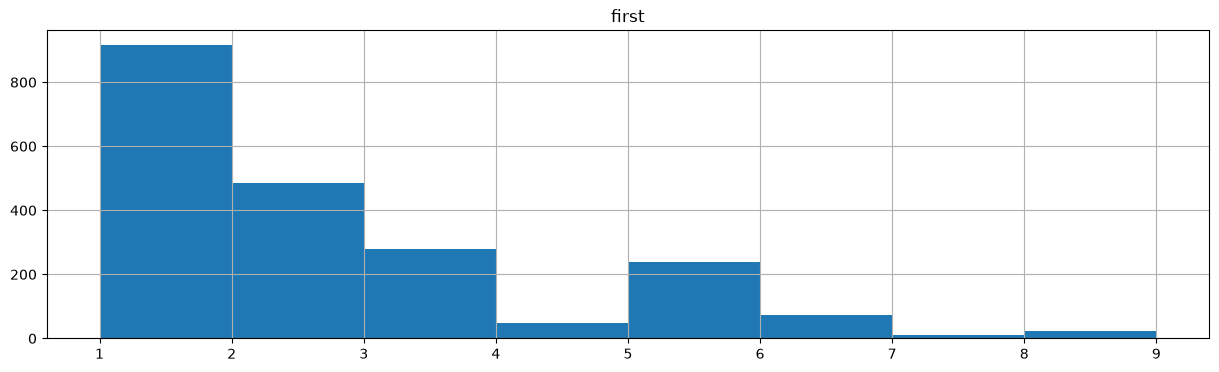

In [7]:
data_b['mode'].hist(figsize=figsize, bins=np.arange(1, 10));

* Moreover, the mode of operation is a _controlled variable_
* ...Hence its distribution might change a lot based on the workload 

## Distribution Discrepancy

**In fact, there is a difference between the training and test distribution**

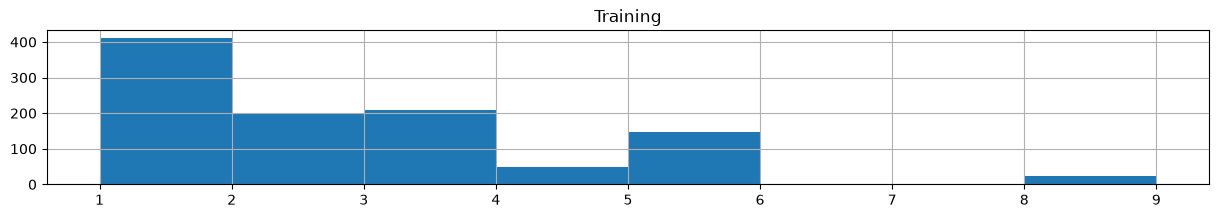

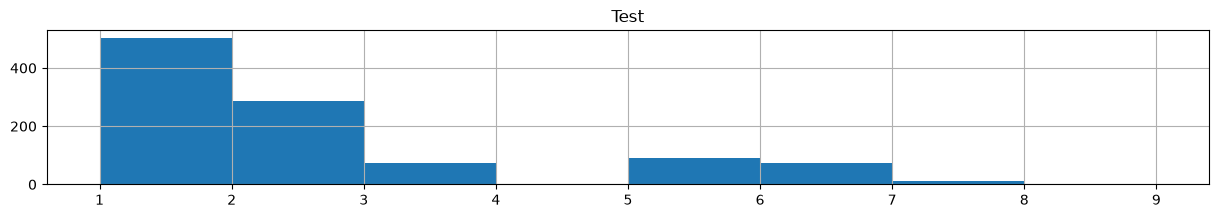

In [8]:
data_b_tr['mode'].hist(figsize=(figsize[0], figsize[1]/2), bins=np.arange(1, 10)); plt.title('Training');
data_b_ts['mode'].hist(figsize=(figsize[0], figsize[1]/2), bins=np.arange(1, 10)); plt.title('Test');

## Training and Expectactions

**This matters because training (typically) means minimizing an _expectation_**

...Ideally, we wish to solve:

$$
\mathop{\text{argmin}}_{\theta}\ \mathrm{E}_{x,y \in P} \left[L_\theta(x, y)] \right]
$$

Where:

* $L$ is the loss function (here including model evaluation)
* ...$\theta$ is the vector of model parameters
* ...And $P$ represents the _target distribution_

Then we use a Monte-Carlo approximation, leading to:

$$
\mathrm{E}_{x,y \in P} \left[L_\theta(x, y) \right] \simeq \frac{1}{m} \sum_{i=1}^m L_\theta(x_i, y_i)
$$

## Sampling Bias

**Problems arise when _our sample is biased_.** E.g. because:

* We can collect data only under certain circumstances
* The dataset is the result of a selection process
* ...Or perhaps due to pure sampling noise

**In this situation:**

We wish to minimize:

$$
\mathrm{E}_{x,y \in P} \left[L_\theta(x, y) \right]
$$

...But we have access to:

$$
(x,y) \sim Q(x, y)
$$

## Handling Sampling Noise

**So, let's recap**

* Our issue is that the training sample is biased
* ...So that it is _not representative_ of the true distribution

> **How can we deal with this problem?**

* A possible solution would be to _alter the training distribution_
* ...So that it _matches more closely_ the test distribution

**...And this is actually something we can do!**

* E.g. we can use data augmentation, or subsampling
* ...Or we can use _sample weights_

## Importance Sampling

**We can _virtually alter_ the training distribution via sample weights**

The key is this useful equality:

$$\begin{align}
\mathrm{E}_{x,y \in P}\left[L(x, y) \right]
& = \int_{x,y} P(x, y) L(x, y)\, dx\,dy \\
& = \int_{x,y} \frac{P(x, y)}{Q(x, y)} Q(x, y) L(x, y)\, dx\,dy \\
& = \mathrm{E}_{x,y \sim Q} \left[ \frac{P(x, y)}{Q(x, y)} L(x, y) \right]
\end{align}$$

* We can estimate an expectation over $P$ via an expectation over $Q$
* ...Provided that we _apply weights_ to the samples

**The approach is called _importance sampling_**

## Importance Sampling

**Let's have a better look at the _importance weight $w_i$_**

For a single example $(x_i, y_i)$, we have:

$$
w_i = \frac{P(x_i, y_i)}{Q(x_i, y_i)} \equiv \frac{p_i}{q_i}
$$

* $Q(x_i, y_i) = q_i$ is the probability in the available distribution
* $P(x_i, y_i) = p_i$ is the probability in the target distribution

**In a Monte-Carlo approximation, we usually need to renormalize the weights:**

$$
\frac{1}{Z} \sum_{i=1}^m \frac{p_i}{q_i} L_\theta(x_i, y_i)
\quad
\text{with:}
\quad
Z = \sum_{i=1}^m \frac{p_i}{q_i}
$$

...Which protects against errors in the estimation of $p_i$ and $q_i$

## Canceling Sampling Bias in Our Problem

**Let's apply the approach to our skinwrapper example**

We know there's an _unwanted sampling bias_ for some modes of operation

* Let $m(x_i)$ be the mode of operation for the $i$-th sample
* Then we can estimate $q_i$ as a frequency of occurrence:

$$
q_i = \frac{1}{n} \left|\{k : m(x_k) = m(x_i), k = 1..n\}\right|
$$

We _don't want_ out anomaly detector to be sensitive to the mode

* So we can assumption a uniform distribution for $p_i$:

$$
p_i = \frac{1}{n}
$$

## Canceling Sampling Bias in Our Problem

**By combining the two we get:**

$$
w_i = \frac{1}{\left|\{k : m(x_k) = m(x_i), k = 1..n\}\right|}
$$

* I.e. the weight is just the inverse of the corresponding mode count

**We can compute the weigths by first obtaining inverse counts for all modes**

In [9]:
vcounts = data_b_tr['mode', 'first'].value_counts()
mode_weight = 1 / vcounts

Then by associating the respective value to every sample:

In [10]:
sample_weight = mode_weight[data_b_tr['mode', 'first']]

## Training with Sample Weights

**Now we can pass training weights to the training algorithm**

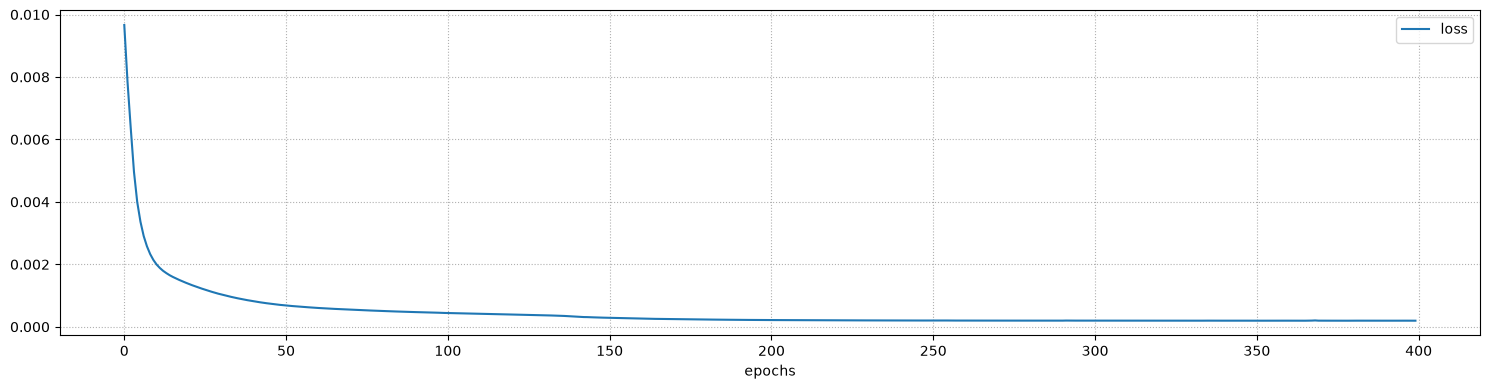

Final loss: 0.0002 (training)


In [11]:
nn2 = util.build_nn_model(input_shape=(len(data_b.columns),), output_shape=len(data_b.columns), hidden=[len(data_b.columns)//2])
history = util.train_nn_model(nn2, data_b_s_tr, data_b_s_tr, loss='mse', validation_split=0.0, batch_size=32, epochs=400, sample_weight=sample_weight)
util.plot_training_history(history, figsize=figsize)

## Evaluation

**Let's check the new reconstruction error**

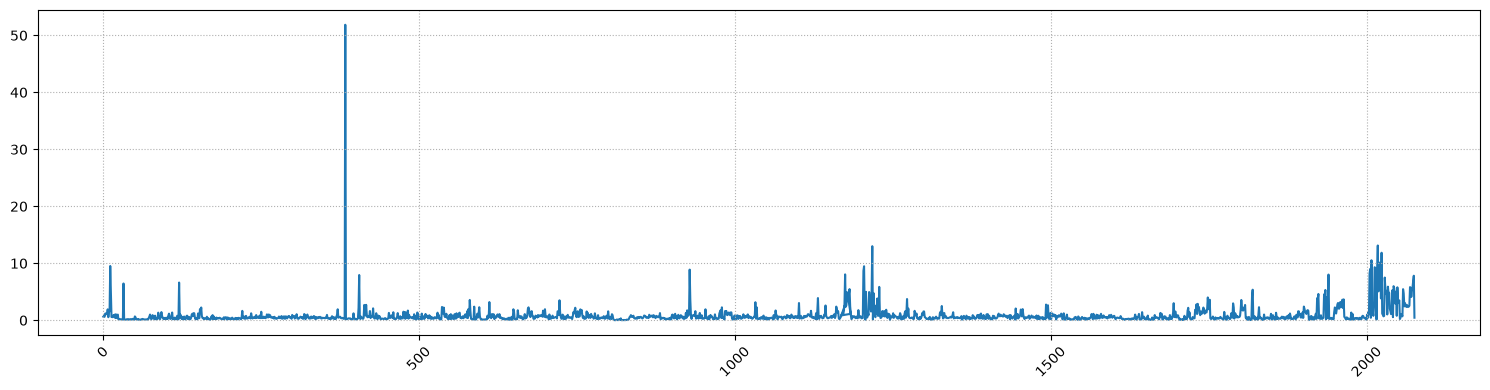

In [12]:
pred2 = nn2.predict(data_b_s, verbose=0)
se2 = (data_b_s - pred2)**2
sse2 = pd.Series(index=data_b.index, data=np.sum(se2, axis=1))
util.plot_series(sse2, figsize=figsize)

At a first glance, the change is not dramatic

## Evaluation

**...But the individual error components are _very different_**

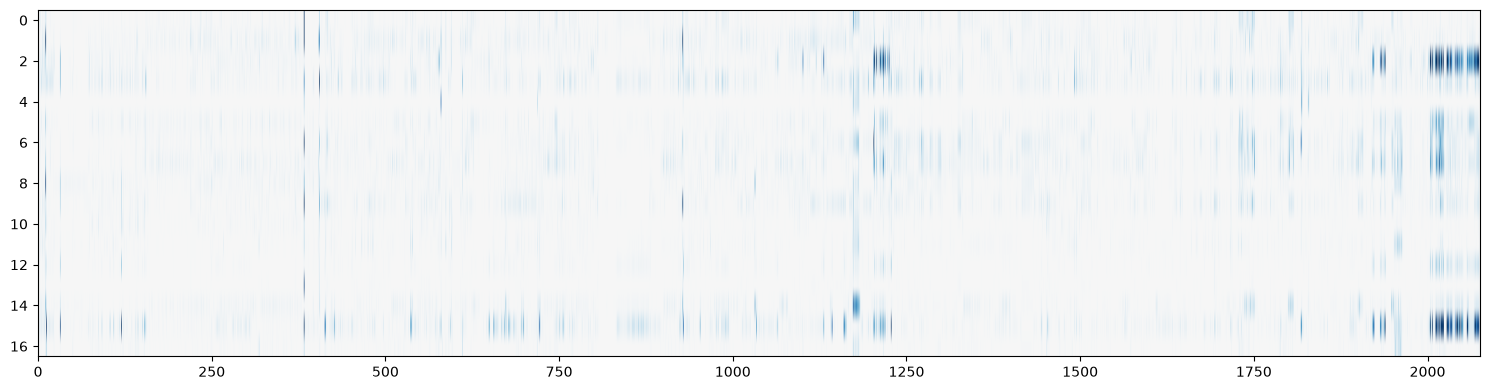

In [13]:
util.plot_dataframe(se2, figsize=figsize)

* Suspected anomalies in the middle sequence have almost disappeared
* ...And there is a much clearer plateau at the end of the signal

# Applications of Importance Sampling

<div class=big>
    <small>Despite its simplicity, importance sampling has many applications</small><br>
Can you identify a few?
</div>

## Class Rebalancing

**The usual _class rebalancing trick_ is a subcase of importance sampling**

In this situation, we assume that some classes are over/under sampled

* Therefore, we estimate $q_i$ using the _class frequency_
* We make a neutral (uniform) assumption on $p_i$
* ...And we define the sample weights for $(x_i, y_i)$ as:

$$
w_i = \frac{1}{n} \frac{n}{\left|\{k : y_k = y_i, k = 1..n\}\right|}
$$

**Watch out during evaluation!**

* Evaluating via (e.g.) accuracy on the unmodified test set _might be a mistake_
* ...Since the weights alter the training distribution

Use a _cost model_ instead, or just a confusion matrix

## Removing Sampling Bias based on Continuous Attribute

**The $p_i$ and $q_i$ values can be probability _densities_**

...Meaning we can remove sampling bias over _continuous attributes_, e.g.:

* Continuous control variables (position, speed, etc.) in industrial machines
* Income or age in socio-economic applications
* Number of reviews in online rating systems

**In this case:**

We can first apply any _density estimation_ approach

* The discrete attribute/class case is the same (we just use a histogram)

Then, it's a good idea to apply some _clipping_, i.e. $q_i = \max(l, \min(u, f(x_i, y_i)))$

* Densities can be very high/low, causing numerical instability

## Removing Sampling Bias due to External Attributes

**It is possible to remove sampling bias due to an "external" process**

Consider an organ transplant program

* Candidate recipients are described by attribute $x_i$ and wait in a queue
* ...from which they may be selected ($y_i = 1$) or not ($y_i = 0$) for surgery
* ...Surgey may then have a positive ($z_i = 1$) or negative ($z_i = 0$) outcome

**Say we want to improve the outcome estimation using ML**

...And possibly use to adjust the selection criterion

* The historical data will be _subject to bias_ due to existing criteria
* ...But if we can estimate the _current selection proabability $P(Y \mid X)$_
* ...We can can use it as $q_i$ for mitigating the bias!

Any classifier with probabilistic output can be used on this purpose

## Sample-specific Variance

**With an _MSE loss_, sample weights have also an alternative interpretation**

In this case we have proved the training problem is equivalent to:

$$
\mathop{\text{argmin}}_{\theta} - \sum_{i=1}^m \log k \exp\left(-\frac{1}{2}(y_i - h_\theta(x_i))^2\right)
$$

* We have simply replaced the generic PDF with a Normal one
* We have $k = 1/\sqrt{2\pi\sigma^2}$ to simplify the notation

**Let's now introduce sample weights, in the form as $1/\sigma_i^2$**

By doing so we get:

$$
\mathop{\text{argmin}}_{\theta} - \sum_{i=1}^m \frac{1}{\sigma_i^2} \log k \exp\left(-\frac{1}{2}(y_i - h_\theta(x_i))^2\right)
$$


## Sample-specific Variance

**Which can be rewritten as:**

$$
\mathop{\text{argmin}}_{\theta} - \sum_{i=1}^m \log k \exp\left(-\frac{1}{2}\left(\frac{y_i - h_\theta(x_i)}{\sigma_i}\right)^2\right)
$$

* This means that sample weights with an MSE loss
* ...Can be interpreted as _inverse sample variances_

**This gives us a way to account for _non-uniform measurement errors_**

* If we know that there is a measurment error with stdev $\sigma_i$ on example $i$
* ...We can account for that by using $1/\sigma_i^2$ as a weight

The result is analogous to using a separate variance model

## ...And Many More

**There are several other applications of Importance Sampling**

* Variance reduction in stochastic integration
* Stochastic smoothing
* Sample re-used in Reinforcement Learning
* ...

We are not going to cover them in this lecture